# Track C — Segmentation: Berka Czech Bank (Longitudinal RFM)

**Track:** C — longitudinal RFM + product enrichment
**Data:** `data/processed/track_c_berka_model.csv` (or raw berka CSVs fallback)
**Methods:** K-Means · GMM (soft membership) · Hierarchical (full dendrogram) · AE optional
**Output:** `artifacts/experiments/comparison_board_track_c.csv`

> **Recommended flag:** Hierarchical is the EDA prior for Track C (small N = 4500, longitudinal).
> Running K-Means and GMM too for a complete comparison.


In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
K_RANGE = range(3, 9)
print('=== IMPORTS OK — Track C: Berka ===')

=== IMPORTS OK — Track C: Berka ===


## 1. Data Loading (with v1.1 enrichment)

Falls back to raw Berka CSVs and attempts to join loan + card flags (v1.1 enrichment).


In [2]:
proc_c_model  = Path('../data/processed/track_c_berka_model.csv')
proc_c_interp = Path('../data/processed/track_c_berka_interpretable.csv')

if proc_c_model.exists() and proc_c_interp.exists():
    df_model_c  = pd.read_csv(proc_c_model)
    df_interp_c = pd.read_csv(proc_c_interp)
    print(f'Loaded pipeline outputs: model={df_model_c.shape} interp={df_interp_c.shape}')
else:
    print('Processed files not found — running inline FE from raw Berka CSVs...')
    berka_candidates = [
        Path('../data/raw/berka-dataset'),
        Path('../data/raw/berka'),
        Path('../data/berka'),
    ]
    berka_dir = next((p for p in berka_candidates if p.exists()), None)
    assert berka_dir, 'Berka folder not found. Expected data/raw/berka-dataset/'

    def read_berka(name):
        for sep in [';', ',']:
            try:
                df = pd.read_csv(berka_dir / f'{name}.csv', sep=sep)
                if len(df.columns) > 1:
                    return df
            except Exception:
                continue
        raise FileNotFoundError(f'{name}.csv not readable')

    trans   = read_berka('trans')
    account = read_berka('account')
    print(f'  trans={trans.shape}  account={account.shape}')

    # Parse dates
    for df_t in [trans, account]:
        if 'date' in df_t.columns and df_t['date'].dtype != 'object':
            df_t['date'] = pd.to_datetime(df_t['date'].astype(str).str.zfill(6),
                                          format='%y%m%d', errors='coerce')

    # Credit / withdrawal split
    trans['is_credit']     = trans['type'].isin(['PRIJEM','CREDIT']).astype(int)
    trans['is_withdrawal'] = trans['type'].isin(['VYDAJ','VYBER','WITHDRAWAL']).astype(int)
    trans['amt_credit']    = trans['amount'] * trans['is_credit']
    trans['amt_withdrawal']= trans['amount'] * trans['is_withdrawal']

    max_date = trans['date'].max()

    agg_c = trans.groupby('account_id').agg(
        Last_Transaction=('date', 'max'),
        Transaction_Count=('trans_id', 'count'),
        Account_Balance=('balance', 'last'),
        Total_Credit=('amt_credit', 'sum'),
        Total_Withdrawal=('amt_withdrawal', 'sum'),
    ).reset_index()
    agg_c['Recency_Days'] = (max_date - agg_c['Last_Transaction']).dt.days
    agg_c.drop(columns=['Last_Transaction'], inplace=True)

    # account['date'] was already parsed to datetime by the loop above.
    # Re-parsing a datetime as '%y%m%d' string would produce NaT (format mismatch).
    # Just compute Account_Age_Days directly.
    account['Account_Age_Days'] = (max_date - account['date']).dt.days

    merged = agg_c.merge(account[['account_id','Account_Age_Days']], on='account_id', how='inner')

    # Optional v1.1 enrichment: join loans and cards
    try:
        loan = read_berka('loan')
        loan['has_loan'] = 1
        merged = merged.merge(loan[['account_id','has_loan']].drop_duplicates(),
                              on='account_id', how='left')
        merged['has_loan'] = merged['has_loan'].fillna(0).astype(int)
        print('  Enriched with loan flag.')
    except Exception as e:
        print(f'  Loan join skipped: {e}')

    try:
        disp = read_berka('disp')
        card = read_berka('card')
        owner_disp = disp[disp['type'].str.upper() == 'OWNER'][['account_id','client_id']]
        card_accts = disp.merge(
            card[['disp_id']].assign(has_card=1), on='disp_id', how='inner'
        )[['account_id','has_card']].drop_duplicates()
        merged = merged.merge(card_accts, on='account_id', how='left')
        merged['has_card'] = merged['has_card'].fillna(0).astype(int)
        print('  Enriched with card flag.')
    except Exception as e:
        print(f'  Card join skipped: {e}')

    # Account_Balance can be NaN (account has transactions but last has null balance).
    # Fill with 0 and only require core RFM columns to be non-null.
    merged['Account_Balance'] = merged['Account_Balance'].fillna(0)
    merged['Total_Credit']    = merged['Total_Credit'].fillna(0)
    merged['Total_Withdrawal']= merged['Total_Withdrawal'].fillna(0)
    core_cols = ['Recency_Days', 'Transaction_Count', 'Account_Age_Days']
    merged.dropna(subset=core_cols, inplace=True)
    print(f'  Rows after dropna (core only): {len(merged):,}')
    df_interp_c = merged.copy()

    # Build model matrix
    id_c   = 'account_id'
    log_c  = ['Account_Balance','Total_Credit','Total_Withdrawal','Account_Age_Days']
    df_model_c = merged.copy()
    for col in log_c:
        if col in df_model_c.columns:
            df_model_c[col] = np.log1p(df_model_c[col].clip(lower=0))
    num_c = [col for col in df_model_c.columns
             if col != id_c and pd.api.types.is_numeric_dtype(df_model_c[col])]
    scaler_c = StandardScaler()
    df_model_c[num_c] = scaler_c.fit_transform(df_model_c[num_c])
    print(f'  Inline FE complete: {df_model_c.shape}')

print(f'Account universe  : {len(df_model_c):,}')
print(f'Feature columns   : {[c for c in df_model_c.columns if c != "account_id"]}')

Processed files not found — running inline FE from raw Berka CSVs...


  trans=(1056320, 10)  account=(4500, 4)


  Enriched with loan flag.
  Enriched with card flag.
  Rows after dropna (core only): 4,500
  Inline FE complete: (4500, 9)
Account universe  : 4,500
Feature columns   : ['Transaction_Count', 'Account_Balance', 'Total_Credit', 'Total_Withdrawal', 'Recency_Days', 'Account_Age_Days', 'has_loan', 'has_card']


In [3]:
ID_COL_C   = 'account_id' if 'account_id' in df_model_c.columns else df_model_c.columns[0]
FEAT_COLS_C = [c for c in df_model_c.columns
               if c != ID_COL_C and pd.api.types.is_numeric_dtype(df_model_c[c])]

X_c = df_model_c[FEAT_COLS_C].fillna(0).values.astype(np.float64)

print(f'Feature matrix : {X_c.shape}')
print(f'Features       : {FEAT_COLS_C}')
print('N is small enough to run all methods on full data.')

Feature matrix : (4500, 8)
Features       : ['Transaction_Count', 'Account_Balance', 'Total_Credit', 'Total_Withdrawal', 'Recency_Days', 'Account_Age_Days', 'has_loan', 'has_card']
N is small enough to run all methods on full data.


## 2. K-Means Sweep


=== K-MEANS SWEEP (Track C) ===


  k=3 | sil=0.314 | DB=1.281 | CH=1383 | sizes={0: 665, 1: 1778, 2: 2057}


  k=4 | sil=0.320 | DB=1.060 | CH=1415 | sizes={0: 2041, 1: 12, 2: 1783, 3: 664}


  k=5 | sil=0.332 | DB=0.904 | CH=1505 | sizes={0: 2016, 1: 1776, 2: 12, 3: 41, 4: 655}


  k=6 | sil=0.363 | DB=0.844 | CH=1727 | sizes={0: 1535, 1: 1596, 2: 655, 3: 12, 4: 661, 5: 41}


  k=7 | sil=0.300 | DB=0.897 | CH=1735 | sizes={0: 658, 1: 934, 2: 675, 3: 1042, 4: 1138, 5: 41, 6: 12}


  k=8 | sil=0.320 | DB=0.857 | CH=1760 | sizes={0: 650, 1: 796, 2: 513, 3: 997, 4: 710, 5: 12, 6: 41, 7: 781}


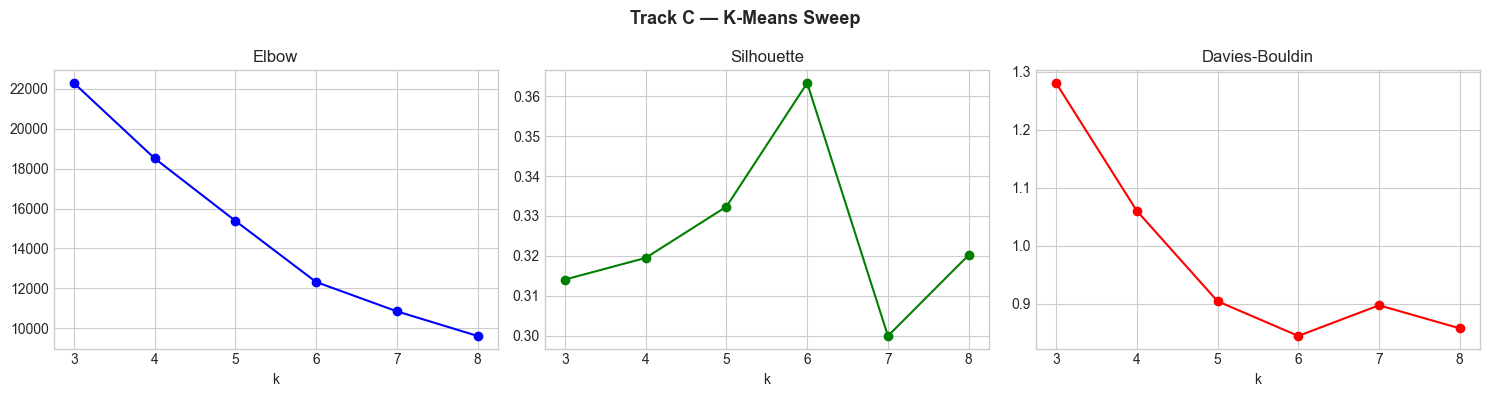

Best k (silhouette): 6


In [4]:
kmeans_c = {}
sil_c, db_c, ch_c = [], [], []

print('=== K-MEANS SWEEP (Track C) ===')
for k in K_RANGE:
    km  = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lbl = km.fit_predict(X_c)
    sil = silhouette_score(X_c, lbl)
    db  = davies_bouldin_score(X_c, lbl)
    ch  = calinski_harabasz_score(X_c, lbl)
    sil_c.append(sil); db_c.append(db); ch_c.append(ch)
    kmeans_c[k] = dict(model=km, labels=lbl, sil=sil, db=db, ch=ch)
    sizes = pd.Series(lbl).value_counts().sort_index().to_dict()
    print(f'  k={k} | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f} | sizes={sizes}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ks = list(K_RANGE)
axes[0].plot(ks, [kmeans_c[k]['model'].inertia_ for k in K_RANGE], 'b-o')
axes[0].set_title('Elbow'); axes[0].set_xlabel('k')
axes[1].plot(ks, sil_c, 'g-o'); axes[1].set_title('Silhouette'); axes[1].set_xlabel('k')
axes[2].plot(ks, db_c,  'r-o'); axes[2].set_title('Davies-Bouldin'); axes[2].set_xlabel('k')
plt.suptitle('Track C — K-Means Sweep', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

best_k_c = ks[int(np.argmax(sil_c))]
print(f'Best k (silhouette): {best_k_c}')

## 3. Gaussian Mixture Model + Soft Membership


=== GMM SWEEP (Track C) ===


  k=3 | sil=0.271 | DB=2.253 | BIC=-86149


  k=4 | sil=0.308 | DB=1.851 | BIC=-109244


  k=5 | sil=0.308 | DB=1.397 | BIC=-117490


  k=6 | sil=0.231 | DB=2.198 | BIC=-124593


  k=7 | sil=0.215 | DB=1.558 | BIC=-120009


  k=8 | sil=0.235 | DB=1.658 | BIC=-128798


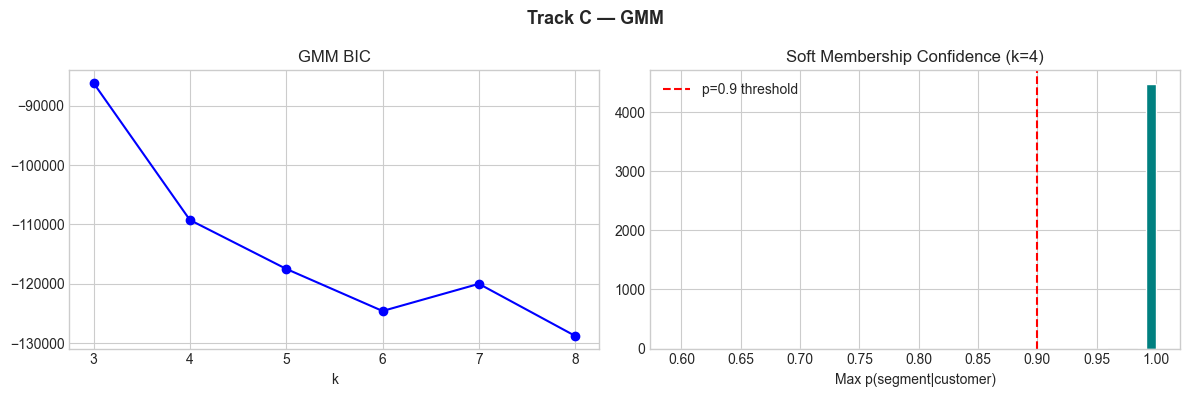

Low-confidence accounts (<0.9): 0.2% → candidates for human review
Best k (GMM silhouette): 4


In [5]:
gmm_c = {}
gmm_c_sil, gmm_c_bic = [], []

print('=== GMM SWEEP (Track C) ===')
for k in K_RANGE:
    g   = GaussianMixture(n_components=k, n_init=5, covariance_type='full',
                          random_state=RANDOM_STATE)
    g.fit(X_c)
    lbl  = g.predict(X_c)
    prob = g.predict_proba(X_c).max(axis=1)
    sil  = silhouette_score(X_c, lbl)
    db   = davies_bouldin_score(X_c, lbl)
    ch   = calinski_harabasz_score(X_c, lbl)
    gmm_c_bic.append(g.bic(X_c))
    gmm_c_sil.append(sil)
    gmm_c[k] = dict(model=g, labels=lbl, confidence=prob, sil=sil, db=db, ch=ch)
    print(f'  k={k} | sil={sil:.3f} | DB={db:.3f} | BIC={gmm_c_bic[-1]:.0f}')

best_k_gmm_c = ks[int(np.argmax(gmm_c_sil))]

# Soft membership distribution for best k
best_conf = gmm_c[best_k_gmm_c]['confidence']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, gmm_c_bic, 'b-o'); axes[0].set_title('GMM BIC'); axes[0].set_xlabel('k')
axes[1].hist(best_conf, bins=50, color='teal', edgecolor='white')
axes[1].axvline(0.9, color='red', ls='--', label='p=0.9 threshold')
axes[1].set_title(f'Soft Membership Confidence (k={best_k_gmm_c})')
axes[1].set_xlabel('Max p(segment|customer)'); axes[1].legend()
plt.suptitle('Track C — GMM', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

low_conf_pct = (best_conf < 0.9).mean() * 100
print(f'Low-confidence accounts (<0.9): {low_conf_pct:.1f}% → candidates for human review')
print(f'Best k (GMM silhouette): {best_k_gmm_c}')

## 4. Hierarchical Clustering + Full Dendrogram

N=4500 is small enough for a full dendrogram — one of Berka's structural advantages.


=== HIERARCHICAL CLUSTERING (Track C — full N, Ward) ===


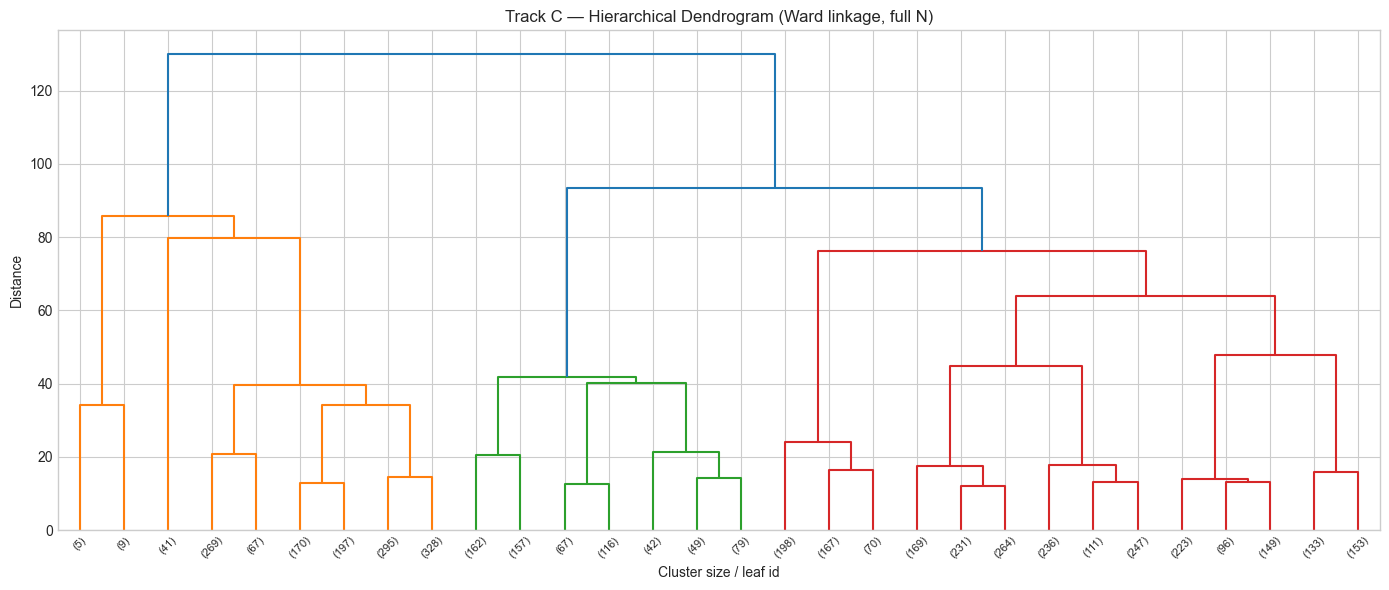

  k=6 | sil=0.335 | DB=0.892 | CH=1509


  k=7 | sil=0.301 | DB=0.952 | CH=1618
Best k (hierarchical): 6


In [6]:
print('=== HIERARCHICAL CLUSTERING (Track C — full N, Ward) ===')

# Full dendrogram (N=4500 is manageable)
Z_c = linkage(X_c, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z_c, ax=ax, truncate_mode='lastp', p=30,
           leaf_rotation=45, leaf_font_size=8)
ax.set_title('Track C — Hierarchical Dendrogram (Ward linkage, full N)')
ax.set_xlabel('Cluster size / leaf id'); ax.set_ylabel('Distance')
plt.tight_layout(); plt.show()

hier_c = {}
for k in [best_k_c, min(best_k_c + 1, 8)]:
    ac  = AgglomerativeClustering(n_clusters=k, linkage='ward')
    lbl = ac.fit_predict(X_c)
    sil = silhouette_score(X_c, lbl)
    db  = davies_bouldin_score(X_c, lbl)
    ch  = calinski_harabasz_score(X_c, lbl)
    hier_c[k] = dict(labels=lbl, sil=sil, db=db, ch=ch)
    print(f'  k={k} | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f}')

best_k_hier_c = max(hier_c, key=lambda k: hier_c[k]['sil'])
print(f'Best k (hierarchical): {best_k_hier_c}')

## 5. Autoencoder (Optional)


PyTorch 2.5.0+cu121 — running optional AE on Track C.

--- AE Track C | latent=4 ---


  ep 10/50 loss=0.07638


  ep 20/50 loss=0.01981


  ep 30/50 loss=0.01516


  ep 40/50 loss=0.01272


  ep 50/50 loss=0.01148


... (3 outputs left out)

  ep 30/50 loss=0.00812


  ep 40/50 loss=0.00629


  ep 50/50 loss=0.00375


  k=6 on z | sil=0.399 | DB=0.759 | CH=2019


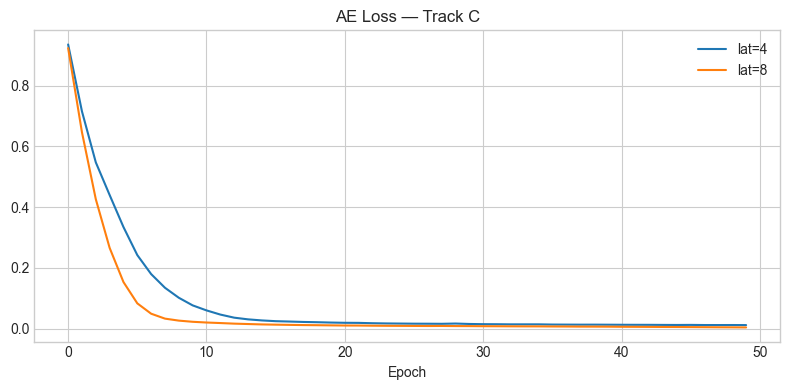

In [7]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_C = True
    print(f'PyTorch {torch.__version__} — running optional AE on Track C.')
except ImportError:
    TORCH_C = False
    print('PyTorch not available — AE skipped for Track C.')

ae_c_results = {}

if TORCH_C:
    class AE_C(nn.Module):
        def __init__(self, n, lat):
            super().__init__()
            self.enc = nn.Sequential(nn.Linear(n,32),nn.ReLU(),nn.Linear(32,lat))
            self.dec = nn.Sequential(nn.Linear(lat,32),nn.ReLU(),nn.Linear(32,n))
        def forward(self, x): z=self.enc(x); return self.dec(z),z

    for lat in [4, 8]:
        print(f'\n--- AE Track C | latent={lat} ---')
        Xt = torch.tensor(X_c, dtype=torch.float32)
        m  = AE_C(X_c.shape[1], lat)
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        crit = nn.MSELoss()
        ld = DataLoader(TensorDataset(Xt), batch_size=128, shuffle=True)
        losses = []
        torch.manual_seed(RANDOM_STATE)
        for ep in range(50):
            m.train(); ep_l=0
            for (b,) in ld:
                opt.zero_grad(); loss=crit(m(b)[0],b); loss.backward(); opt.step()
                ep_l += loss.item()
            losses.append(ep_l/len(ld))
            if (ep+1)%10==0: print(f'  ep {ep+1}/50 loss={losses[-1]:.5f}')
        m.eval()
        with torch.no_grad(): _,z = m(Xt)
        z = z.numpy()
        km_z = KMeans(n_clusters=best_k_c, n_init=20, random_state=RANDOM_STATE)
        lbl  = km_z.fit_predict(z)
        sil  = silhouette_score(z, lbl)
        db   = davies_bouldin_score(z, lbl)
        ch   = calinski_harabasz_score(z, lbl)
        ae_c_results[lat] = dict(z=z, labels=lbl, losses=losses, sil=sil, db=db, ch=ch)
        print(f'  k={best_k_c} on z | sil={sil:.3f} | DB={db:.3f} | CH={ch:.0f}')

    if ae_c_results:
        fig, ax = plt.subplots(figsize=(8,4))
        for lat, r in ae_c_results.items():
            ax.plot(r['losses'], label=f'lat={lat}')
        ax.set_title('AE Loss — Track C'); ax.set_xlabel('Epoch'); ax.legend()
        plt.tight_layout(); plt.show()

## 6. Stability Analysis


=== STABILITY (K-Means k=6) === ARI=0.864 ± 0.170


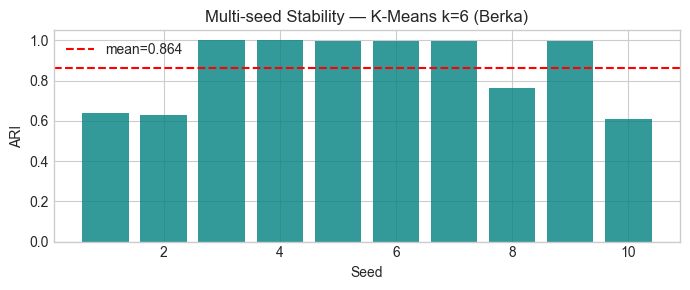

In [8]:
N_SEEDS_C = 10
ari_c = []
base_c = KMeans(n_clusters=best_k_c, n_init=20, random_state=0).fit_predict(X_c)

for seed in range(1, N_SEEDS_C + 1):
    lbl_s = KMeans(n_clusters=best_k_c, n_init=5, random_state=seed).fit_predict(X_c)
    ari_c.append(adjusted_rand_score(base_c, lbl_s))

mean_c_ari = float(np.mean(ari_c))
print(f'=== STABILITY (K-Means k={best_k_c}) === ARI={mean_c_ari:.3f} ± {np.std(ari_c):.3f}')

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(1, N_SEEDS_C+1), ari_c, color='teal', alpha=0.8)
ax.axhline(mean_c_ari, color='red', ls='--', label=f'mean={mean_c_ari:.3f}')
ax.set_title(f'Multi-seed Stability — K-Means k={best_k_c} (Berka)')
ax.set_xlabel('Seed'); ax.set_ylabel('ARI'); ax.set_ylim(0, 1.05)
ax.legend(); plt.tight_layout(); plt.show()

## 7. Comparison Board


In [9]:
rows_c = []

for k, r in kmeans_c.items():
    rows_c.append(dict(run_id=f'c_kmeans_k{k}', track='berka', method='kmeans',
                       k=k, latent_dim='-',
                       silhouette=round(r['sil'],4), db_index=round(r['db'],4),
                       ch_index=round(r['ch'],0),
                       stability_ari=round(mean_c_ari,3) if k==best_k_c else None,
                       recommended=False))

for k, r in gmm_c.items():
    rows_c.append(dict(run_id=f'c_gmm_k{k}', track='berka', method='gmm',
                       k=k, latent_dim='-',
                       silhouette=round(r['sil'],4), db_index=round(r['db'],4),
                       ch_index=round(r['ch'],0), stability_ari=None,
                       recommended=False))

for k, r in hier_c.items():
    rows_c.append(dict(run_id=f'c_hier_k{k}', track='berka', method='hierarchical',
                       k=k, latent_dim='-',
                       silhouette=round(r['sil'],4), db_index=round(r['db'],4),
                       ch_index=round(r['ch'],0), stability_ari=None,
                       recommended=(k==best_k_hier_c)))

for lat, r in ae_c_results.items():
    rows_c.append(dict(run_id=f'c_ae_lat{lat}_k{best_k_c}', track='berka',
                       method='ae_kmeans', k=best_k_c, latent_dim=lat,
                       silhouette=round(r['sil'],4), db_index=round(r['db'],4),
                       ch_index=round(r['ch'],0), stability_ari=None, recommended=False))

board_c = pd.DataFrame(rows_c).sort_values('silhouette', ascending=False).reset_index(drop=True)

out_c = Path('../artifacts/experiments')
out_c.mkdir(parents=True, exist_ok=True)
board_c.to_csv(out_c / 'comparison_board_track_c.csv', index=False)

print('=== COMPARISON BOARD — Track C ===')
display(board_c)

=== COMPARISON BOARD — Track C ===


,run_id,track,method,k,latent_dim,silhouette,db_index,ch_index,stability_ari,recommended
0,c_ae_lat4_k6,berka,ae_kmeans,6,4,0.4172,0.7307,3474.0,NaN,False
1,c_ae_lat8_k6,berka,ae_kmeans,6,8,0.3988,0.7594,2019.0,NaN,False
2,c_kmeans_k6,berka,kmeans,6,-,0.3633,0.8443,1727.0,0.864,False
3,c_hier_k6,berka,hierarchical,6,-,0.3348,0.8917,1509.0,NaN,True
4,c_kmeans_k5,berka,kmeans,5,-,0.3323,0.9042,1505.0,NaN,False
5,c_kmeans_k8,berka,kmeans,8,-,0.3202,0.8574,1760.0,NaN,False
6,c_kmeans_k4,berka,kmeans,4,-,0.3195,1.0603,1415.0,NaN,False
7,c_kmeans_k3,berka,kmeans,3,-,0.3141,1.2810,1383.0,NaN,False
8,c_gmm_k4,berka,gmm,4,-,0.3084,1.8510,710.0,NaN,False
9,c_gmm_k5,berka,gmm,5,-,0.3079,1.3969,681.0,NaN,False


## 8. Visualizations & Profiles


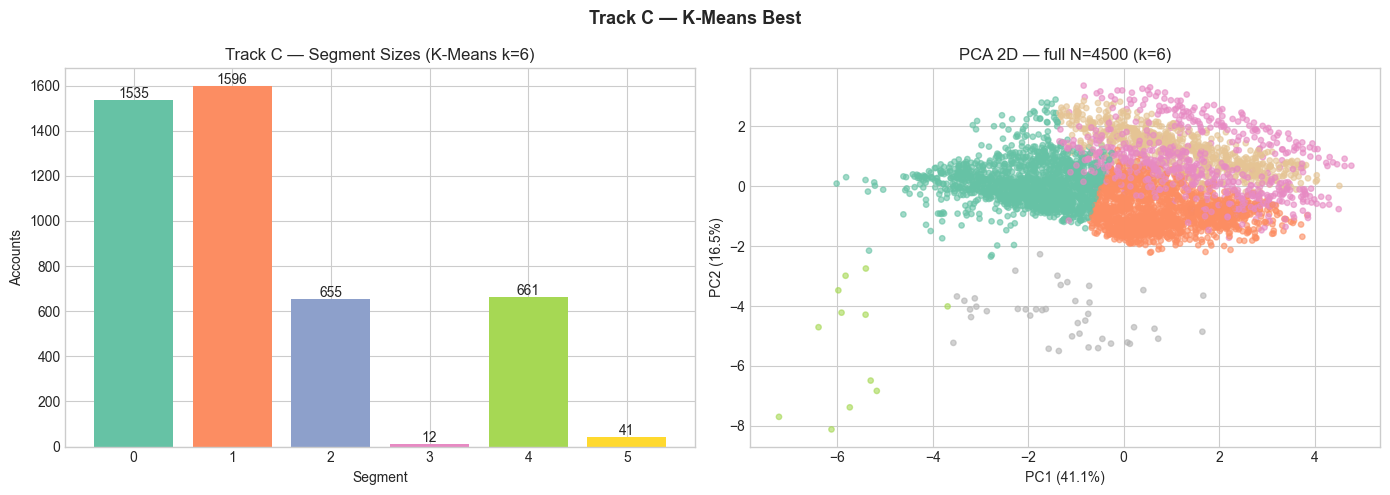

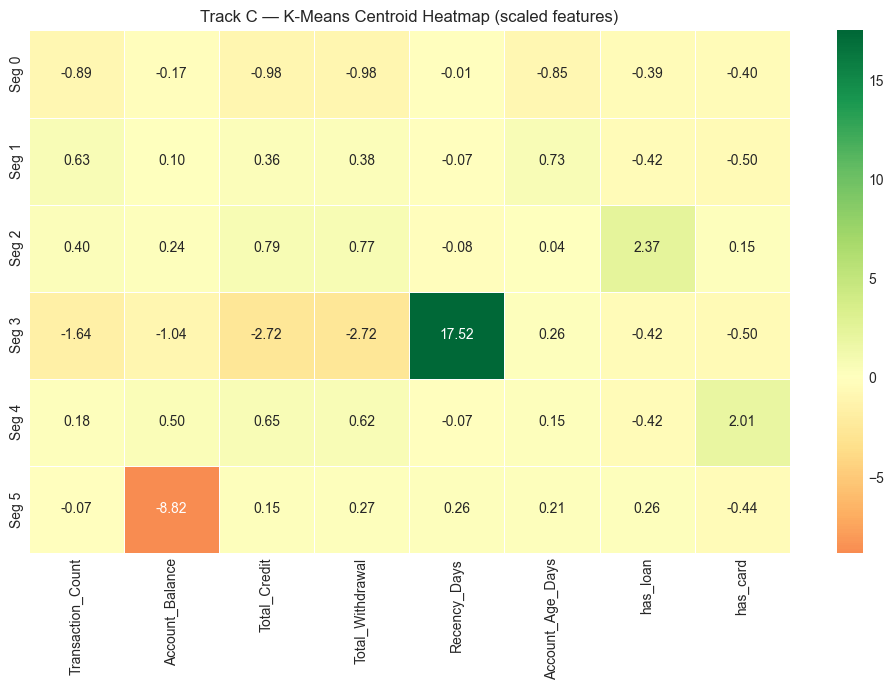

=== SEGMENT PROFILES (interpretable scale) ===


,Transaction_Count,Account_Balance,Total_Credit,Total_Withdrawal,Recency_Days,Account_Age_Days,has_loan,has_card
segment,,,,,,,,
0,122.37,31853.49,218344.30,186490.34,2.40,782.67,0.01,0.04
1,314.43,44640.19,840883.46,796241.76,0.38,1649.17,0.00,0.00
2,285.83,51821.67,1217418.63,1165585.45,0.27,1238.85,1.00,0.26
3,27.33,10098.73,33490.42,23491.67,539.17,1379.17,0.00,0.00
4,256.94,65357.61,1094647.62,1029288.96,0.47,1312.77,0.00,1.00
5,226.07,-6468.20,704652.42,711127.99,10.68,1341.20,0.24,0.02


In [10]:
k_c = best_k_c
lbl_c = kmeans_c[k_c]['labels']

# ── Segment sizes ─────────────────────────────────────────────
seg_c = pd.Series(lbl_c).value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette_c = sns.color_palette('Set2', k_c)
axes[0].bar(seg_c.index, seg_c.values, color=palette_c)
for i, v in zip(seg_c.index, seg_c.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=10)
axes[0].set_title(f'Track C — Segment Sizes (K-Means k={k_c})')
axes[0].set_xlabel('Segment'); axes[0].set_ylabel('Accounts')

# ── PCA 2D ────────────────────────────────────────────────────
pca_c = PCA(n_components=2, random_state=RANDOM_STATE)
X_c_pca = pca_c.fit_transform(X_c)
axes[1].scatter(X_c_pca[:,0], X_c_pca[:,1], c=lbl_c, cmap='Set2', alpha=0.6, s=15)
axes[1].set_title(f'PCA 2D — full N={len(X_c)} (k={k_c})')
axes[1].set_xlabel(f'PC1 ({pca_c.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca_c.explained_variance_ratio_[1]*100:.1f}%)')
plt.suptitle('Track C — K-Means Best', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# ── Centroid heatmap ──────────────────────────────────────────
cen_c = kmeans_c[k_c]['model'].cluster_centers_
c_df_c = pd.DataFrame(cen_c, columns=FEAT_COLS_C,
                      index=[f'Seg {i}' for i in range(k_c)])
fig, ax = plt.subplots(figsize=(max(10, len(FEAT_COLS_C)), k_c + 1))
sns.heatmap(c_df_c, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=0.5, ax=ax)
ax.set_title('Track C — K-Means Centroid Heatmap (scaled features)')
plt.tight_layout(); plt.show()

# ── Segment profiles ──────────────────────────────────────────
prof_c = df_interp_c.copy().reset_index(drop=True)
prof_c['segment'] = lbl_c
feat_c_interp = [c for c in df_interp_c.columns
                 if c != ID_COL_C and pd.api.types.is_numeric_dtype(df_interp_c[c])]
seg_prof_c = prof_c.groupby('segment')[feat_c_interp].mean().round(2)
print('=== SEGMENT PROFILES (interpretable scale) ===')
display(seg_prof_c)

## 9. Three-Track Summary

Run this cell after all three notebooks have completed to see the full cross-track comparison.


In [11]:
best_c = board_c.iloc[0]
print('=' * 60)
print('TRACK C — SEGMENTATION COMPLETE')
print('=' * 60)
print(f'  Best run   : {best_c["run_id"]}')
print(f'  Method     : {best_c["method"]}')
print(f'  k          : {best_c["k"]}')
print(f'  Silhouette : {best_c["silhouette"]}')
print(f'  DB Index   : {best_c["db_index"]}')
print(f'  Stability  : {best_c["stability_ari"]}')
print()
print('=== THREE-TRACK COMPARISON BOARDS ===')
for fname in ['comparison_board_track_a.csv',
              'comparison_board_track_b.csv',
              'comparison_board_track_c.csv']:
    p = Path('../artifacts/experiments') / fname
    if p.exists():
        df_tmp = pd.read_csv(p)
        best_tmp = df_tmp.sort_values('silhouette', ascending=False).iloc[0]
        print(f'  {fname}: best={best_tmp["run_id"]} sil={best_tmp["silhouette"]}')
    else:
        print(f'  {fname}: not found (run that notebook first)')
print()
print('Manual rubric scoring next:')
print('  1. Review centroid heatmaps for each best run')
print('  2. Score interpretability (0-1) per run')
print('  3. Score application distinctness (0-1) per run')
print('  4. Apply rubric.yaml weights → champion')
print()
print('Champion selection memo → reports/champion_selection_memo.md')

TRACK C — SEGMENTATION COMPLETE
  Best run   : c_ae_lat4_k6
  Method     : ae_kmeans
  k          : 6
  Silhouette : 0.4172
  DB Index   : 0.7307
  Stability  : nan

=== THREE-TRACK COMPARISON BOARDS ===
  comparison_board_track_a.csv: best=a_ae_ld8_k6 sil=0.3317
  comparison_board_track_b.csv: not found (run that notebook first)
  comparison_board_track_c.csv: best=c_ae_lat4_k6 sil=0.4172

Manual rubric scoring next:
  1. Review centroid heatmaps for each best run
  2. Score interpretability (0-1) per run
  3. Score application distinctness (0-1) per run
  4. Apply rubric.yaml weights → champion

Champion selection memo → reports/champion_selection_memo.md
